<a href="https://colab.research.google.com/github/SHREYANSH-GUPTA-008/Case_Studies_MLE/blob/main/%09E-Commerce-Customer-Segmentation/customer_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

# Load dataset
df = pd.read_excel('/content/Online Retail.xlsx')

# Display first 5 records
print("First 5 Records:")
display(df.head())

# Dataset information
print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

First 5 Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Dataset Shape: (541909, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Statistical Summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Remove rows without CustomerID
df = df.dropna(subset=['CustomerID'])

# Remove duplicate records
df = df.drop_duplicates()

# Convert CustomerID to integer
df['CustomerID'] = df['CustomerID'].astype(int)

# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Remove cancelled transactions
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Remove invalid quantities and prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

print("\nDataset Shape After Cleaning:", df.shape)

display(df.head())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Dataset Shape After Cleaning: (392692, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [5]:
# Calculate total transaction amount
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

# Reference date for Recency calculation
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM values
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

# Rename columns
rfm.columns = ['Recency', 'Frequency', 'Monetary']

print("RFM Dataset:")
display(rfm.head())

print("\nRFM Dataset Shape:", rfm.shape)

RFM Dataset:


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40



RFM Dataset Shape: (4338, 3)


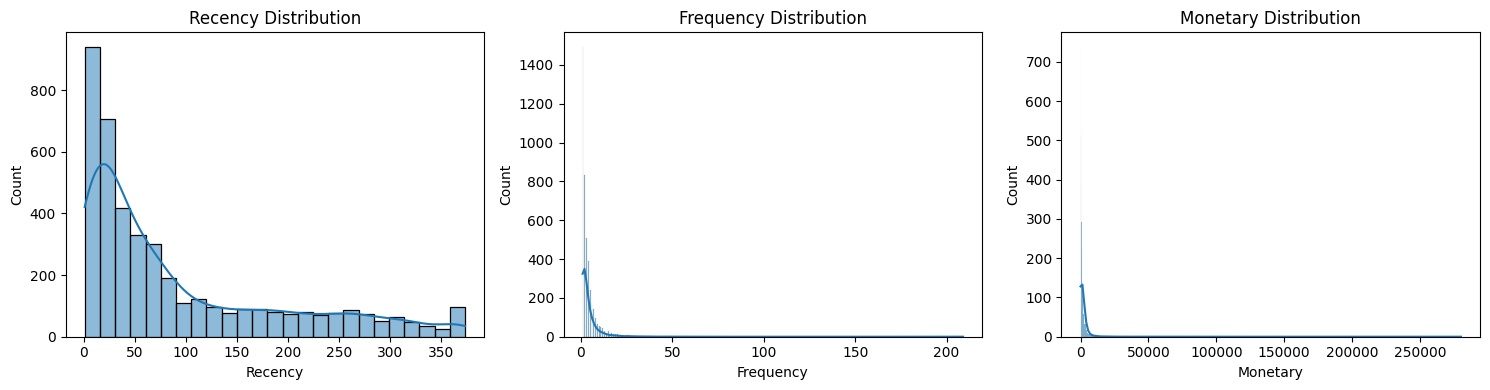

In [6]:
# Plot RFM distributions

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(rfm['Recency'], kde=True)
plt.title('Recency Distribution')

plt.subplot(1, 3, 2)
sns.histplot(rfm['Frequency'], kde=True)
plt.title('Frequency Distribution')

plt.subplot(1, 3, 3)
sns.histplot(rfm['Monetary'], kde=True)
plt.title('Monetary Distribution')

plt.tight_layout()
plt.show()

In [7]:
# Apply StandardScaler
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)

# Convert scaled data into DataFrame
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

display(rfm_scaled_df.head())

,Recency,Frequency,Monetary
CustomerID,,,
12346,2.334574,-0.425097,8.363010
12347,-0.905340,0.354417,0.251699
12348,-0.175360,-0.035340,-0.027988
12349,-0.735345,-0.425097,-0.032406
12350,2.174578,-0.425097,-0.190812


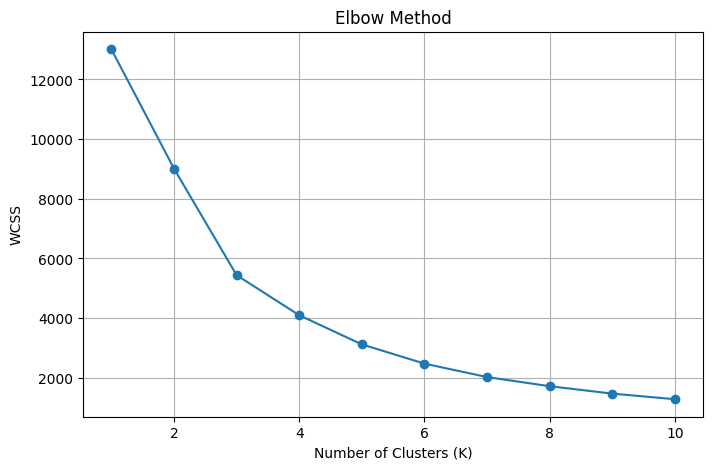

In [8]:
# Elbow Method

wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [9]:
# Apply K-Means

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['KMeans_Cluster'] = kmeans.fit_predict(rfm_scaled)

print("K-Means Cluster Distribution:")
print(rfm['KMeans_Cluster'].value_counts().sort_index())

K-Means Cluster Distribution:
KMeans_Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64


In [10]:
# Apply DBSCAN

dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

rfm['DBSCAN_Cluster'] = dbscan.fit_predict(rfm_scaled)

print("DBSCAN Cluster Distribution:")
print(rfm['DBSCAN_Cluster'].value_counts().sort_index())

# Number of clusters excluding noise
n_clusters = len(set(rfm['DBSCAN_Cluster'])) - (
    1 if -1 in rfm['DBSCAN_Cluster'].values else 0
)

# Number of noise points
n_noise = list(rfm['DBSCAN_Cluster']).count(-1)

print("\nNumber of DBSCAN Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1      54
 0    4284
Name: count, dtype: int64

Number of DBSCAN Clusters: 1
Number of Noise Points: 54


In [11]:
# Apply PCA

pca = PCA(n_components=2)

pca_result = pca.fit_transform(rfm_scaled)

rfm['PCA1'] = pca_result[:, 0]
rfm['PCA2'] = pca_result[:, 1]

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Variance Explained:",
      sum(pca.explained_variance_ratio_))

Explained Variance Ratio:
[0.55473084 0.30252713]
Total Variance Explained: 0.8572579763919153


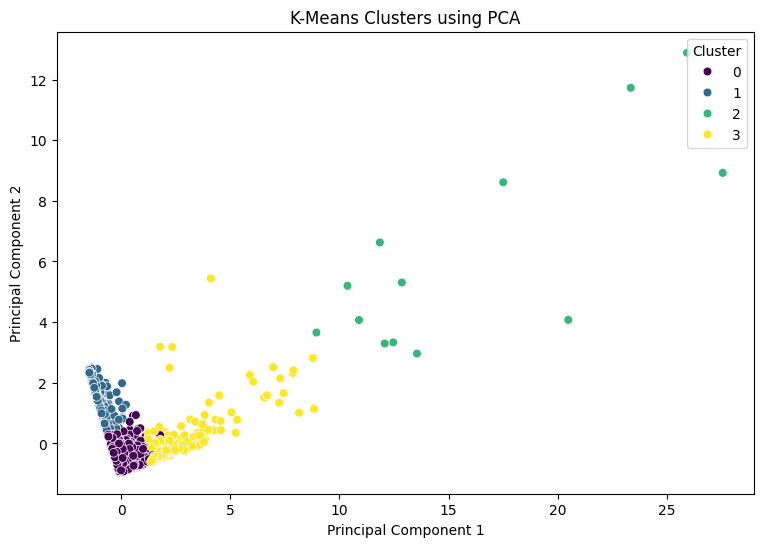

In [12]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=rfm['PCA1'],
    y=rfm['PCA2'],
    hue=rfm['KMeans_Cluster'],
    palette='viridis',
    s=40
)

plt.title('K-Means Clusters using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

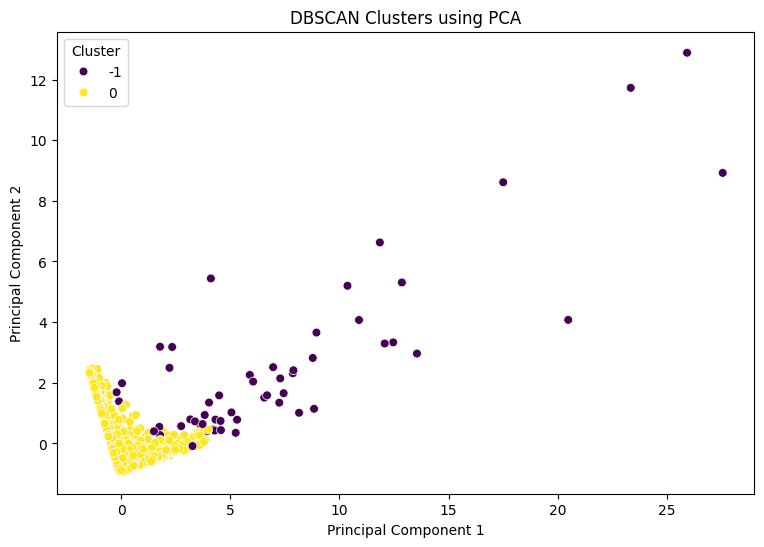

In [13]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=rfm['PCA1'],
    y=rfm['PCA2'],
    hue=rfm['DBSCAN_Cluster'],
    palette='viridis',
    s=40
)

plt.title('DBSCAN Clusters using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

In [14]:
# Apply t-SNE

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init='pca',
    learning_rate='auto'
)

tsne_result = tsne.fit_transform(rfm_scaled)

rfm['TSNE1'] = tsne_result[:, 0]
rfm['TSNE2'] = tsne_result[:, 1]

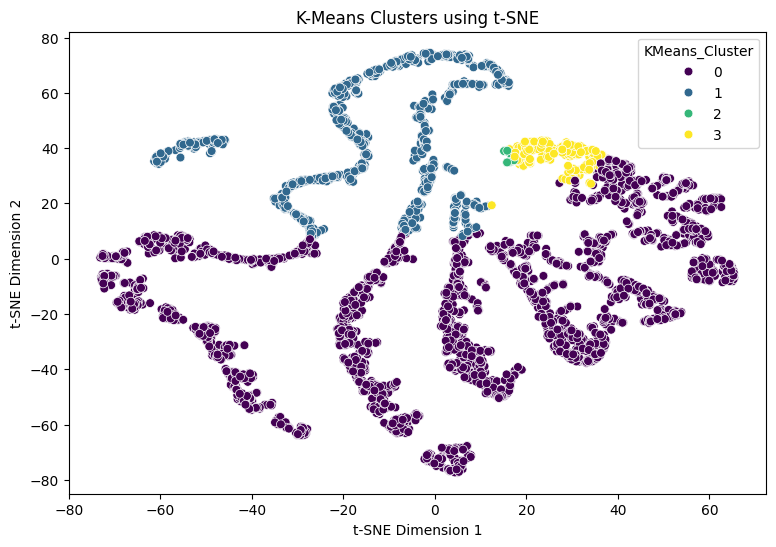

In [15]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=rfm['TSNE1'],
    y=rfm['TSNE2'],
    hue=rfm['KMeans_Cluster'],
    palette='viridis',
    s=40
)

plt.title('K-Means Clusters using t-SNE')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.show()

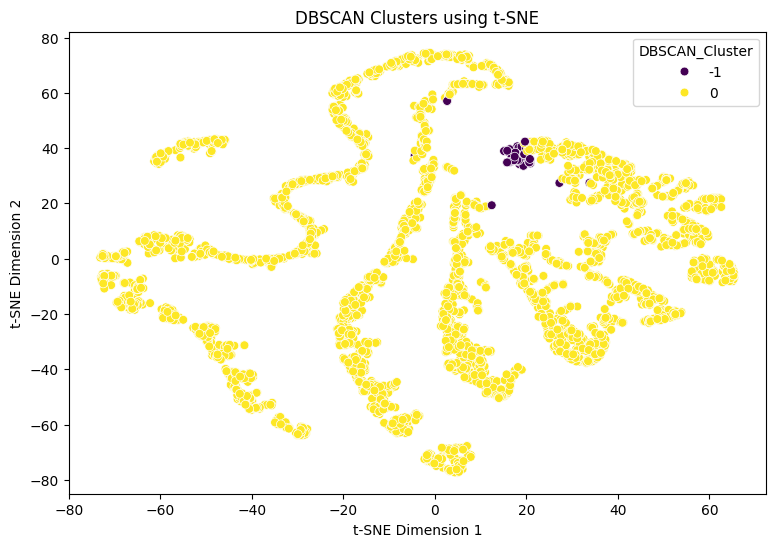

In [16]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=rfm['TSNE1'],
    y=rfm['TSNE2'],
    hue=rfm['DBSCAN_Cluster'],
    palette='viridis',
    s=40
)

plt.title('DBSCAN Clusters using t-SNE')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.show()

In [17]:
# K-Means Cluster Analysis

kmeans_analysis = rfm.groupby('KMeans_Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].mean().round(2)

print("K-Means Cluster Analysis:")
display(kmeans_analysis)

K-Means Cluster Analysis:


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,43.70,3.68,1353.63
1,248.08,1.55,478.85
2,7.38,82.54,127187.96
3,15.50,22.33,12690.50


In [18]:
# DBSCAN Cluster Analysis

dbscan_analysis = rfm.groupby('DBSCAN_Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].mean().round(2)

print("DBSCAN Cluster Analysis:")
display(dbscan_analysis)

DBSCAN Cluster Analysis:


,Recency,Frequency,Monetary
DBSCAN_Cluster,,,
-1,43.31,43.24,54098.4
0,93.16,3.78,1392.6


In [19]:
# Generate Marketing Personas

personas = []

for cluster in kmeans_analysis.index:

    recency = kmeans_analysis.loc[cluster, 'Recency']
    frequency = kmeans_analysis.loc[cluster, 'Frequency']
    monetary = kmeans_analysis.loc[cluster, 'Monetary']

    if recency <= kmeans_analysis['Recency'].median() and \
       frequency >= kmeans_analysis['Frequency'].median() and \
       monetary >= kmeans_analysis['Monetary'].median():

        persona = "Loyal High-Value Customers"
        strategy = "Reward with loyalty points and exclusive offers."

    elif recency > kmeans_analysis['Recency'].median():

        persona = "At-Risk or Inactive Customers"
        strategy = "Send re-engagement emails and comeback discounts."

    elif monetary >= kmeans_analysis['Monetary'].median():

        persona = "Big Spenders"
        strategy = "Offer premium products and personalized recommendations."

    else:

        persona = "Regular or Low-Value Customers"
        strategy = "Use product recommendations and cross-selling."

    personas.append({
        'Cluster': cluster,
        'Persona': persona,
        'Marketing Strategy': strategy
    })

persona_df = pd.DataFrame(personas)

print("Customer Marketing Personas:")
display(persona_df)

Customer Marketing Personas:


,Cluster,Persona,Marketing Strategy
0,0,At-Risk or Inactive Customers,Send re-engagement emails and comeback discounts.
1,1,At-Risk or Inactive Customers,Send re-engagement emails and comeback discounts.
2,2,Loyal High-Value Customers,Reward with loyalty points and exclusive offers.
3,3,Loyal High-Value Customers,Reward with loyalty points and exclusive offers.


In [20]:
# K-Means Silhouette Score

kmeans_score = silhouette_score(
    rfm_scaled,
    rfm['KMeans_Cluster']
)

print("K-Means Silhouette Score:", round(kmeans_score, 4))


# DBSCAN Silhouette Score

dbscan_labels = rfm['DBSCAN_Cluster'].values

mask = dbscan_labels != -1

valid_labels = dbscan_labels[mask]

if len(set(valid_labels)) >= 2 and \
   len(set(valid_labels)) < len(valid_labels):

    dbscan_score = silhouette_score(
        rfm_scaled[mask],
        valid_labels
    )

    print("DBSCAN Silhouette Score:", round(dbscan_score, 4))

else:
    print("DBSCAN Silhouette Score cannot be calculated reliably.")

K-Means Silhouette Score: 0.6162
DBSCAN Silhouette Score cannot be calculated reliably.


In [21]:
# Save complete RFM results
rfm.to_csv('customer_segmentation_results.csv')

# Save K-Means analysis
kmeans_analysis.to_csv('kmeans_cluster_analysis.csv')

# Save DBSCAN analysis
dbscan_analysis.to_csv('dbscan_cluster_analysis.csv')

# Save marketing personas
persona_df.to_csv('marketing_personas.csv', index=False)

print("All results saved successfully!")

All results saved successfully!


In [22]:
from google.colab import files

files.download('customer_segmentation_results.csv')
files.download('kmeans_cluster_analysis.csv')
files.download('dbscan_cluster_analysis.csv')
files.download('marketing_personas.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>